In [1]:
import numpy as np
import cobra
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pickle
import sys
sys.path.append('../../')
from helper_function import *
plt.rcParams['font.family'] = 'Arial'

cobra.Configuration().solver = "glpk"

In [2]:
with open('../../FBAsolution/M9_sufficient_423_1_proteome_weakbg.pkl', 'rb') as pickle_file:
    data4 = pickle.load(pickle_file)
    all_total_nutrient_count4 = data4['all_total_nutrient_count']
    all_total_intake4 = data4['all_total_intake']
    all_growth_rate4 = data4['all_growth_rate']
    all_random_medium4 = data4['all_random_medium']
    all_met_flux4 = data4['all_met_flux']
    del data4

with open("../../FBAsolution/M9_sufficient_423_0_weakbg_dropout.pkl", "rb") as f:
    data = pickle.load(f)
    dropout_growth_rate = data['dropout_growth_rate']   
    dropout_medium = data['dropout_medium']
    dropout_met_flux = data['dropout_met_flux']
    del data

with open('../../Coarse_graining_result/clustered_nodes_c20_s44_pq1_relabeled.pkl', 'rb') as f:
    cluster_nodes = pickle.load(f)

In [3]:
def node_proteome_cost(met_flux, node_id, cluster_nodes):
        
    grouped_rec = [rec for rec in cluster_nodes[node_id] if 'EX_' not in rec]
    #grouped_flux = {rec: value for rec, value in met_flux if rec+'_fwd' in grouped_rec  or rec+'_bwd' in grouped_rec}

    grouped_flux = {rec: value for rec, value in met_flux if (rec+'_fwd' in grouped_rec and value > 0) or (rec+'_bwd' in grouped_rec and value < 0)}

    node_proteome_cost = 0
    for rec, flux in grouped_flux.items():
        proteome_cost = abs(flux)
        node_proteome_cost += proteome_cost

    return node_proteome_cost

def graph_node_proteome_cost(met_flux, cluster_nodes):
    graph_proteome_cost = {}

    for node_id in range(20):
        temp = node_proteome_cost(met_flux, node_id, cluster_nodes)
        graph_proteome_cost[node_id] = temp

    return graph_proteome_cost

def sector_flux_distribution_vector(met_flux, cluster_nodes):

    n_sectors = len(cluster_nodes)

    # 收集每个 sector 的 flux
    sector_flux = []


    for rxn_idx, s in cluster_nodes.items():
        grouped_rec = [rec for rec in cluster_nodes[rxn_idx] if 'EX_' not in rec]
        grouped_flux = {rec: abs(value) for rec, value in met_flux if (rec+'_fwd' in grouped_rec and value > 0) or (rec+'_bwd' in grouped_rec and value < 0)}
        sector_flux.append(list(grouped_flux.values()))
    
    # e = np.array([sum(sector) for sector in sector_flux])
    # print(e / e.sum())


    total_entropy = [] 
    for s in range(n_sectors):
        flux_arr = np.array(sector_flux[s], dtype=float)
        if flux_arr.size == 0 or np.all(flux_arr == 0):
            gini = 0.0
            entropy = 0.0
        else:
            # 归一化成分布
            p = flux_arr / flux_arr.sum()
            # entropy
            p_nonzero = p[p > 0]
            entropy = -np.sum(p_nonzero * np.log(p_nonzero))
            # gini（用原始 flux 或 p 都可以，这里用 p）
        total_entropy.append(entropy)
    return np.array(total_entropy)


In [4]:
from typing import List, Tuple, Optional
from dataclasses import dataclass

@dataclass
class Sample:
    E: np.ndarray      # shape (n,)
    Y: float
    e: np.ndarray

def build_samples_from_origin(all_met_flux, all_growth_rate, cluster_nodes) -> List[Sample]:
    samples = []
    for j in range(len(all_met_flux)):
        for i in range(len(all_met_flux[j])):
            if all_growth_rate[j][i] == 0:
                continue
            E_tmp = list(graph_node_proteome_cost(all_met_flux[j][i], cluster_nodes).values())
            try:
                with np.errstate(divide='raise', invalid='raise'):
                    E_arr = np.asarray(E_tmp, dtype=float)
                    E = E_arr / E_arr.sum()
            except FloatingPointError:
                continue

            total_proteome = sum([abs(value) for key, value in all_met_flux[j][i]])
            Y = all_growth_rate[j][i]
            samples.append(Sample(E=np.asarray(E, dtype=float),
                                Y=Y, e=sector_flux_distribution_vector(all_met_flux[j][i], cluster_nodes)))
    return samples


def build_samples_from_dropout(all_met_flux, all_growth_rate, cluster_nodes) -> List[Sample]:
    samples = []
    for j in range(len(all_met_flux)):
            if all_growth_rate[j] == 0:
                continue
            E_tmp = list(graph_node_proteome_cost(all_met_flux[j], cluster_nodes).values())
            try:
                with np.errstate(divide='raise', invalid='raise'):
                    E_arr = np.asarray(E_tmp, dtype=float)
                    E = E_arr / E_arr.sum()
            except FloatingPointError:
                continue

            total_proteome = sum([abs(value) for key, value in all_met_flux[j]])
            Y = all_growth_rate[j]
            samples.append(Sample(E=np.asarray(E, dtype=float),
                                Y=Y, e=sector_flux_distribution_vector(all_met_flux[j], cluster_nodes)))
    return samples

In [5]:
dropout_samples = build_samples_from_dropout(dropout_met_flux[51], dropout_growth_rate[51], cluster_nodes)
origin_samples = build_samples_from_origin(all_met_flux4, all_growth_rate4, cluster_nodes)

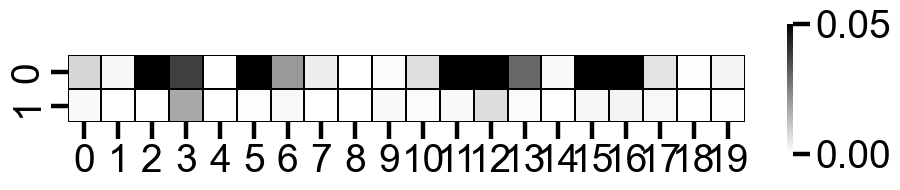

In [ ]:
from matplotlib.colors import LogNorm

set_panel_style(scale=4)
E_matrix = np.vstack([origin_samples[51].E, dropout_samples[2].E, dropout_samples[6].E])
eps=1e-6
E1 = E_matrix[0]
E2 = E_matrix[1]
E3 = E_matrix[2]

# delta_1 = np.divide((E1 - E2), E1, out=np.zeros_like(E1, dtype=float), where=(E1 > 1e-3))
# delta_2 = np.divide((E1 - E3), E1, out=np.zeros_like(E1, dtype=float), where=(E1 > 1e-3))

delta_1 = abs(np.array(E1 - E2))
delta_2 = abs(np.array(E1 - E3))

delta = np.vstack([abs(delta_2), abs(delta_1)])

fig, ax = plt.subplots(figsize=(10, 2.5))

import matplotlib.colors as mcolors

cmap = mcolors.LinearSegmentedColormap.from_list("white_black", ["white", "black"])

sns.heatmap(
    delta,
    ax=ax,
    cmap=cmap,
    vmin=0, vmax=0.05,
    #norm=LogNorm(vmin=1e-1, vmax=1),
    linewidths=0.2,
    linecolor="#000000",
    xticklabels=True,   # If you have sector names, you can replace True with a list
)
ax.set_aspect('equal', 'box')

ax.set_ylabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

# Standard mode: remove top/right spines (also applicable to heatmap)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
# fig.savefig("Figure3D.pdf", format="pdf", bbox_inches="tight", pad_inches=0.5)
plt.show()